In [1]:
# maps for max, min, mean, range of variability - what time is the sampling bias the highest (all minus veg only, all minus impervious only, etc)
# violins to show the mean change and the max change. 
# midday, midnight, mean (as min max might be at different times for different pixels)
# same for rh. 

#####################################################################################
##### Plot to create images of the daily raster summaries and sampling data bia #####
#####################################################################################

import rasterio
import rasterio.mask
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap # for plotting
import os
import ptitprince as pt
import seaborn as sns
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import string


base_dir = r"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters"
training_set_list = ['All_LC', 'Shaded_trained','Unshaded_trained','Impervious_trained', 'Vegetation_trained']
variable_name_list = ['AT','RH']

tif_filename = ['hourly_mean.tif','daily_mean_min.tif', 'daily_mean_max.tif']
tif_filenames_24_hrs = [f"hour_{hour:02d}_mean.tif" for hour in range(24)]

#lcz_world_cover_path = r"C:\Users\Sarah\Documents\Python_Scripts\DDL\Sensor_Network\Heat_model_Durham_Raleigh\data\final_rasters\lcz_WorldCover_2021_final.tif"

# Look at midday (12), midnight (0)
hours_of_interest = [0, 12]  

# functions
# to load the rasters
def load_raster(path):
    with rasterio.open(path) as src:
        data = src.read(1, masked=True)
    return data

# to plot the rasters and save them in the plots folder 
def plot_raster(data, title, save_path, cmap='Reds', vmin=None, vmax=None):
    plt.figure(figsize=(8,6))
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax) if vmin is not None else None
    plt.imshow(data, cmap=cmap, norm=norm)
    plt.colorbar()
    plt.title(title)
    plt.tight_layout()
    plt.savefig(save_path)
    plt.close()

# to compute stats for each raster file 
def compute_stats(rasters):
    stack = np.ma.stack(rasters)
    mean = stack.mean(axis=0)
    min_val = stack.min(axis=0)
    max_val = stack.max(axis=0)
    range_val = max_val - min_val
    return mean, min_val, max_val, range_val

# for computing the sampling bias from training on only one type of landcover or shading type 
def compute_bias(reference, target):
    return  target - reference


hourly_mean.tif Shaded_trained range -0.9905777 0.3397274
hourly_mean.tif Unshaded_trained range -0.3567524 0.90382767
hourly_mean.tif Impervious_trained range -0.6234112 1.0789471
hourly_mean.tif Vegetation_trained range -0.64868927 0.9942379
daily_mean_min.tif Shaded_trained range -0.43608856 0.49959755
daily_mean_min.tif Unshaded_trained range -0.70197105 0.3498993
daily_mean_min.tif Impervious_trained range -0.27724838 0.4478264
daily_mean_min.tif Vegetation_trained range -0.7052765 0.47727585
daily_mean_max.tif Shaded_trained range -2.6505203 0.4578762
daily_mean_max.tif Unshaded_trained range -0.699543 2.3554344
daily_mean_max.tif Impervious_trained range -1.8816853 2.1961613
daily_mean_max.tif Vegetation_trained range -1.5483513 2.339161


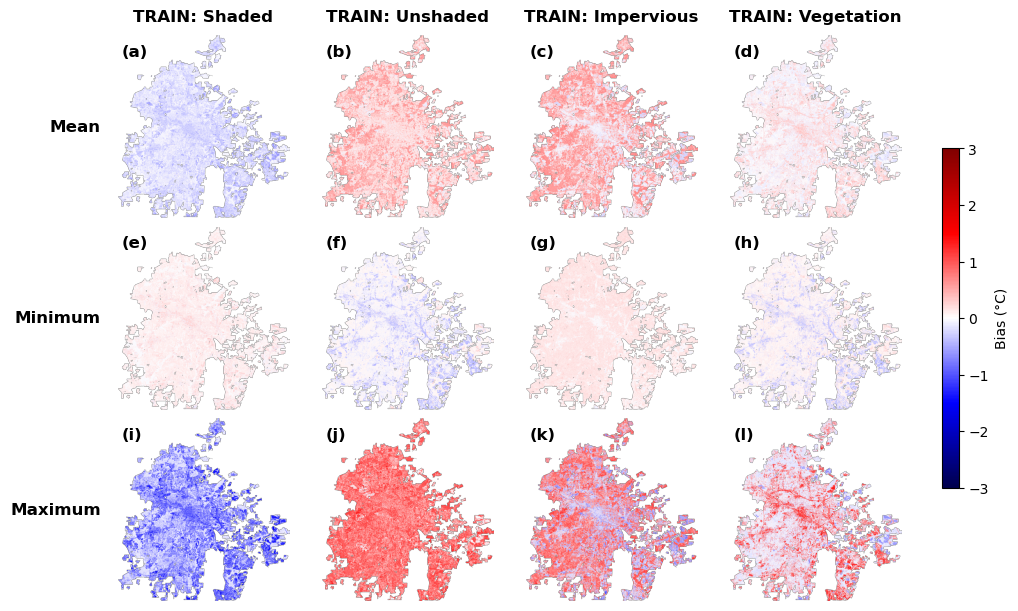

In [3]:

base_dir = r"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\AT"
training_set_list = ['All_LC', 'Shaded_trained','Unshaded_trained','Impervious_trained', 'Vegetation_trained']
training_titles = ['All Landcover','TRAIN: Shaded','TRAIN: Unshaded','TRAIN: Impervious','TRAIN: Vegetation']
comparison_sets = training_set_list[1:]  # compare against All_LC
tif_filename = ['hourly_mean.tif','daily_mean_min.tif', 'daily_mean_max.tif']
metric_titles = ['Mean','Minimum', 'Maximum']


panel_labels = list(string.ascii_lowercase) 

# Function to read raster
def read_raster(path):
    with rasterio.open(path) as src:
        return src.read(1), src.transform

# Plot bias function
def plot_bias_grid(tif_base_path, saved_plot_name):
    n_rows = len(tif_filename)
    n_cols = len(comparison_sets)
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols/2, 4*n_rows/2), constrained_layout=True)
    
    
    if n_rows == 1: axes = np.array([axes])
    if n_cols == 1: axes = axes[:, np.newaxis]
    
    label_idx = 0
    
    for i, tif_file in enumerate(tif_filename):
        # Load All_LC raster
        all_lc_raster, transform = read_raster(f"{tif_base_path}/All_LC/{tif_file}")
        
        for j, comp_set in enumerate(comparison_sets):
            comp_raster, _ = read_raster(f"{tif_base_path}/{comp_set}/{tif_file}")
            bias = comp_raster - all_lc_raster
            print(tif_file,comp_set,'range', np.nanmin(bias), np.nanmax(bias))
            
            ax = axes[i, j]
            im = ax.imshow(bias, cmap='seismic', vmin=-3, vmax=3)
            ax.axis('off')
            
            # Panel label
            ax.text(0.02, 0.95, f"({panel_labels[label_idx]})", transform=ax.transAxes,
                    fontsize=12, fontweight='bold', va='top', ha='left', color='black')
            label_idx += 1
            # Row titles (on left)
            if j == 0:
                ax.text(-0.1, 0.5, metric_titles[i], transform=ax.transAxes,
                        fontsize=12, fontweight='bold', va='center', ha='right')
            
            # Column titles (top row only)
            if i == 0:
                ax.set_title(training_titles[j+1], fontsize=12, fontweight='bold', pad=10)
    
            # Only show y-axis labels on the first column
            #if j == 0:
            #    ax.set_ylabel(tif_file, fontsize=10)
    
    # Shared colorbar
    cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.6, label='Bias (°C)')
    plt.savefig(saved_plot_name, dpi=600)

# tif_base_path = 
plot_bias_grid(base_dir, saved_plot_name='AT_bias_maps.png')


hour_02_mean.tif Shaded_trained range -0.56360626 0.6434822
hour_02_mean.tif Unshaded_trained range -0.64121246 0.5684891
hour_02_mean.tif Impervious_trained range -0.4237919 0.48283958
hour_02_mean.tif Vegetation_trained range -0.49529076 0.6927242
hour_10_mean.tif Shaded_trained range -2.9811573 0.8607178
hour_10_mean.tif Unshaded_trained range -1.0693035 2.912199
hour_10_mean.tif Impervious_trained range -1.483654 1.9203014
hour_10_mean.tif Vegetation_trained range -2.2113323 2.3281422
hour_14_mean.tif Shaded_trained range -2.5262375 0.6944752
hour_14_mean.tif Unshaded_trained range -0.7462845 2.1575775
hour_14_mean.tif Impervious_trained range -1.8004837 1.9207363
hour_14_mean.tif Vegetation_trained range -1.227251 2.6562595


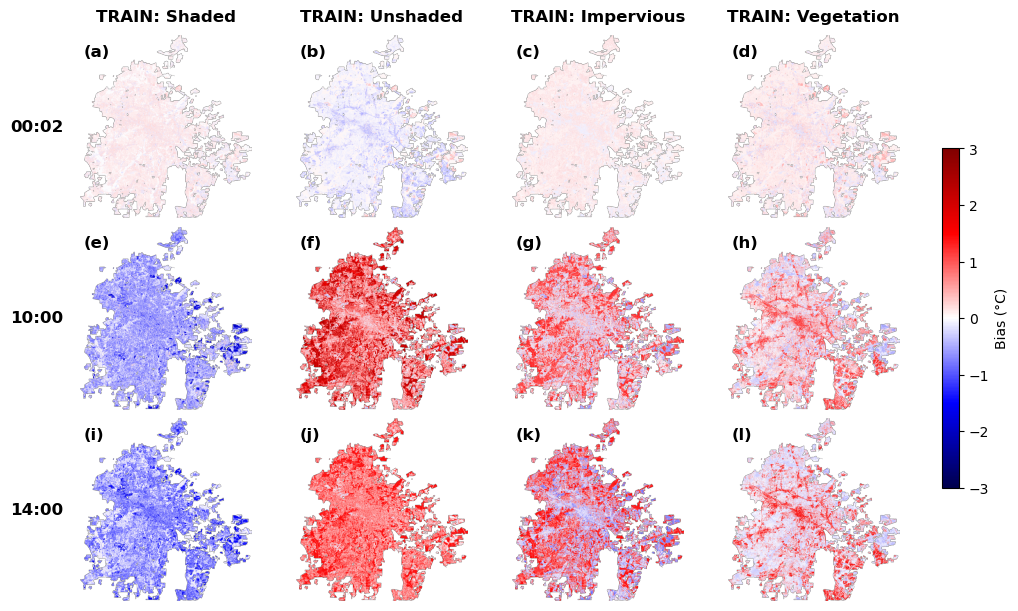

In [32]:
base_dir = r"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\AT"
training_set_list = ['All_LC', 'Shaded_trained','Unshaded_trained','Impervious_trained', 'Vegetation_trained']
training_titles = ['All Landcover','TRAIN: Shaded','TRAIN: Unshaded','TRAIN: Impervious','TRAIN: Vegetation']
comparison_sets = training_set_list[1:]  # compare against All_LC
tif_filename = ['hour_02_mean.tif','hour_10_mean.tif', 'hour_14_mean.tif']
metric_titles = ['00:02','10:00', '14:00']


panel_labels = list(string.ascii_lowercase) 

# Function to read raster
def read_raster(path):
    with rasterio.open(path) as src:
        return src.read(1), src.transform

# Plot bias function
def plot_bias_grid(tif_base_path, saved_plot_name):
    n_rows = len(tif_filename)
    n_cols = len(comparison_sets)
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols/2, 4*n_rows/2), constrained_layout=True)
    
    
    if n_rows == 1: axes = np.array([axes])
    if n_cols == 1: axes = axes[:, np.newaxis]
    
    label_idx = 0
    
    for i, tif_file in enumerate(tif_filename):
        # Load All_LC raster
        all_lc_raster, transform = read_raster(f"{tif_base_path}/All_LC/{tif_file}")
        
        for j, comp_set in enumerate(comparison_sets):
            comp_raster, _ = read_raster(f"{tif_base_path}/{comp_set}/{tif_file}")
            bias = comp_raster - all_lc_raster
            print(tif_file,comp_set,'range', np.nanmin(bias), np.nanmax(bias))
            
            ax = axes[i, j]
            im = ax.imshow(bias, cmap='seismic', vmin=-3, vmax=3)
            ax.axis('off')
            
            # Panel label
            ax.text(0.02, 0.95, f"({panel_labels[label_idx]})", transform=ax.transAxes,
                    fontsize=12, fontweight='bold', va='top', ha='left', color='black')
            label_idx += 1
            # Row titles (on left)
            if j == 0:
                ax.text(-0.1, 0.5, metric_titles[i], transform=ax.transAxes,
                        fontsize=12, fontweight='bold', va='center', ha='right')
            
            # Column titles (top row only)
            if i == 0:
                ax.set_title(training_titles[j+1], fontsize=12, fontweight='bold', pad=10)
    
            # Only show y-axis labels on the first column
            #if j == 0:
            #    ax.set_ylabel(tif_file, fontsize=10)
    
    # Shared colorbar
    cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.6, label='Bias (°C)')
    plt.savefig(saved_plot_name, dpi=600)

# tif_base_path = 
plot_bias_grid(base_dir, saved_plot_name='AT_bias_maps_based_on_time.png')


hourly_mean.tif Shaded_trained range -3.237175 3.0400772
hourly_mean.tif Unshaded_trained range -4.596756 2.125969
hourly_mean.tif Impervious_trained range -7.604637 2.0440903
hourly_mean.tif Vegetation_trained range -3.5341644 5.1271667
daily_mean_min.tif Shaded_trained range -4.353718 7.3071823
daily_mean_min.tif Unshaded_trained range -7.125725 2.4564056
daily_mean_min.tif Impervious_trained range -11.449814 3.6917992
daily_mean_min.tif Vegetation_trained range -6.5130157 7.141968
daily_mean_max.tif Shaded_trained range -2.917984 1.315422
daily_mean_max.tif Unshaded_trained range -1.7635269 2.3047485
daily_mean_max.tif Impervious_trained range -3.0752182 2.4472504
daily_mean_max.tif Vegetation_trained range -2.327217 3.0388718


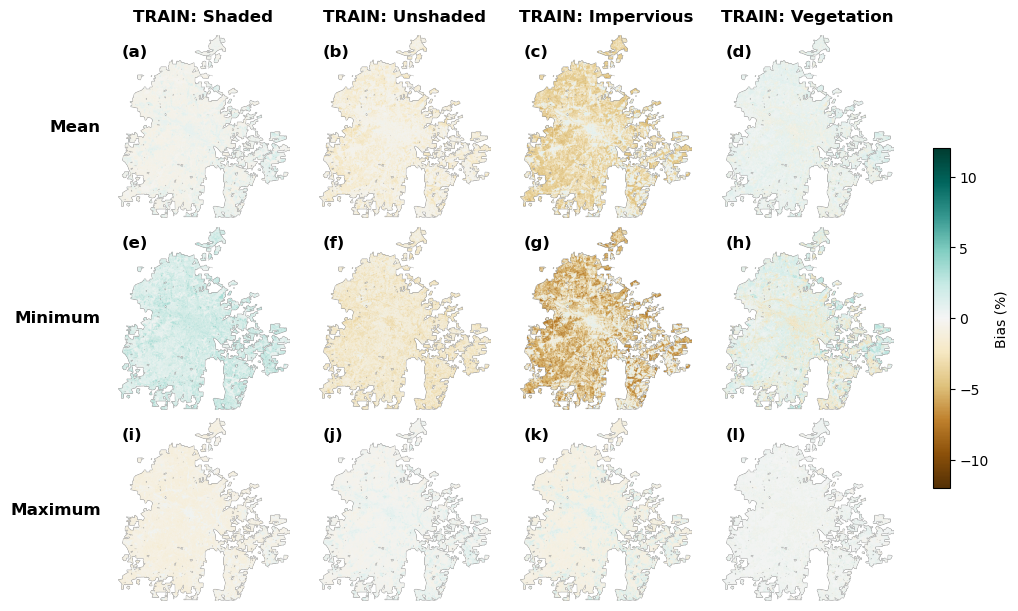

In [31]:
base_dir = r"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\RH"
training_set_list = ['All_LC', 'Shaded_trained','Unshaded_trained','Impervious_trained', 'Vegetation_trained']
training_titles = ['All Landcover','TRAIN: Shaded','TRAIN: Unshaded','TRAIN: Impervious','TRAIN: Vegetation']
comparison_sets = training_set_list[1:]  # compare against All_LC
tif_filename = ['hourly_mean.tif','daily_mean_min.tif', 'daily_mean_max.tif']
metric_titles = ['Mean','Minimum', 'Maximum']

panel_labels = list(string.ascii_lowercase) 

# Function to read raster
def read_raster(path):
    with rasterio.open(path) as src:
        return src.read(1), src.transform

# Plot bias function
def plot_bias_grid(tif_base_path,saved_plot_name):
    n_rows = len(tif_filename)
    n_cols = len(comparison_sets)
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols/2, 4*n_rows/2), constrained_layout=True)
    
    
    if n_rows == 1: axes = np.array([axes])
    if n_cols == 1: axes = axes[:, np.newaxis]
    
    label_idx = 0
    
    for i, tif_file in enumerate(tif_filename):
        # Load All_LC raster
        all_lc_raster, transform = read_raster(f"{tif_base_path}/All_LC/{tif_file}")
        
        for j, comp_set in enumerate(comparison_sets):
            comp_raster, _ = read_raster(f"{tif_base_path}/{comp_set}/{tif_file}")
            bias = comp_raster - all_lc_raster
            print(tif_file,comp_set,'range', np.nanmin(bias), np.nanmax(bias))
            
            ax = axes[i, j]
            im = ax.imshow(bias, cmap='BrBG', vmin=-12, vmax=12)  
            ax.axis('off')
            
            # Panel label
            ax.text(0.02, 0.95, f"({panel_labels[label_idx]})", transform=ax.transAxes,
                    fontsize=12, fontweight='bold', va='top', ha='left', color='black')
            label_idx += 1
            # Row titles (on left)
            if j == 0:
                ax.text(-0.1, 0.5, metric_titles[i], transform=ax.transAxes,
                        fontsize=12, fontweight='bold', va='center', ha='right')
            
            # Column titles (top row only)
            if i == 0:
                ax.set_title(training_titles[j+1], fontsize=12, fontweight='bold', pad=10)
    
            # Only show y-axis labels on the first column
            #if j == 0:
            #    ax.set_ylabel(tif_file, fontsize=10)
    
    # Shared colorbar
    cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.6, label='Bias (%)')
    plt.savefig(saved_plot_name, dpi=600)

# tif_base_path = 
plot_bias_grid(base_dir,saved_plot_name='RH_bias_maps.png')


hour_00_mean.tif Shaded_trained range -4.4424744 1.897789
hour_00_mean.tif Unshaded_trained range -2.5226364 2.2475204
hour_00_mean.tif Impervious_trained range -5.141876 2.8154755
hour_00_mean.tif Vegetation_trained range -4.015785 4.1032104
hour_10_mean.tif Shaded_trained range -5.01577 11.980583
hour_10_mean.tif Unshaded_trained range -15.193893 4.820389
hour_10_mean.tif Impervious_trained range -14.359894 3.3244019
hour_10_mean.tif Vegetation_trained range -6.3163223 12.211922
hour_14_mean.tif Shaded_trained range -4.287346 7.3026123
hour_14_mean.tif Unshaded_trained range -7.38081 2.3152199
hour_14_mean.tif Impervious_trained range -11.674942 4.05175
hour_14_mean.tif Vegetation_trained range -8.530212 6.9432983


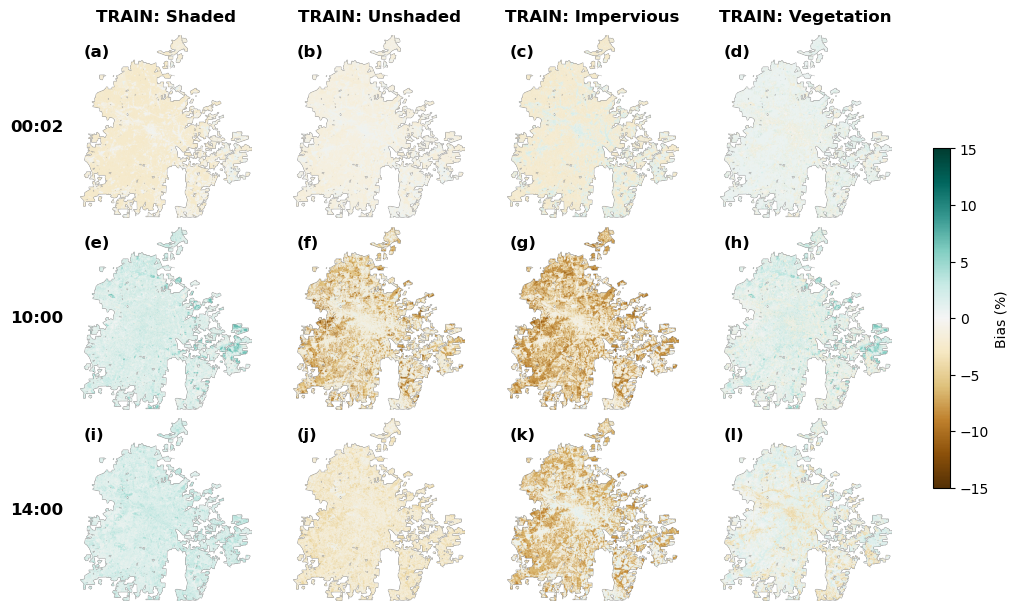

In [33]:
base_dir = r"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\RH"
training_set_list = ['All_LC', 'Shaded_trained','Unshaded_trained','Impervious_trained', 'Vegetation_trained']
training_titles = ['All Landcover','TRAIN: Shaded','TRAIN: Unshaded','TRAIN: Impervious','TRAIN: Vegetation']
comparison_sets = training_set_list[1:]  # compare against All_LC
tif_filename = ['hour_00_mean.tif','hour_10_mean.tif', 'hour_14_mean.tif']
metric_titles = ['00:02','10:00', '14:00']

panel_labels = list(string.ascii_lowercase) 

# Function to read raster
def read_raster(path):
    with rasterio.open(path) as src:
        return src.read(1), src.transform

# Plot bias function
def plot_bias_grid(tif_base_path,saved_plot_name):
    n_rows = len(tif_filename)
    n_cols = len(comparison_sets)
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols/2, 4*n_rows/2), constrained_layout=True)
    
    
    if n_rows == 1: axes = np.array([axes])
    if n_cols == 1: axes = axes[:, np.newaxis]
    
    label_idx = 0
    
    for i, tif_file in enumerate(tif_filename):
        # Load All_LC raster
        all_lc_raster, transform = read_raster(f"{tif_base_path}/All_LC/{tif_file}")
        
        for j, comp_set in enumerate(comparison_sets):
            comp_raster, _ = read_raster(f"{tif_base_path}/{comp_set}/{tif_file}")
            bias = comp_raster - all_lc_raster
            print(tif_file,comp_set,'range', np.nanmin(bias), np.nanmax(bias))
            
            ax = axes[i, j]
            im = ax.imshow(bias, cmap='BrBG', vmin=-15, vmax=15)  
            ax.axis('off')
            
            # Panel label
            ax.text(0.02, 0.95, f"({panel_labels[label_idx]})", transform=ax.transAxes,
                    fontsize=12, fontweight='bold', va='top', ha='left', color='black')
            label_idx += 1
            # Row titles (on left)
            if j == 0:
                ax.text(-0.1, 0.5, metric_titles[i], transform=ax.transAxes,
                        fontsize=12, fontweight='bold', va='center', ha='right')
            
            # Column titles (top row only)
            if i == 0:
                ax.set_title(training_titles[j+1], fontsize=12, fontweight='bold', pad=10)
    
            # Only show y-axis labels on the first column
            #if j == 0:
            #    ax.set_ylabel(tif_file, fontsize=10)
    
    # Shared colorbar
    cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.6, label='Bias (%)')
    plt.savefig(saved_plot_name, dpi=600)

# tif_base_path = 
plot_bias_grid(base_dir,saved_plot_name='RH_bias_maps_based_on_time.png')


Bias range: -1.8084984 1.258398


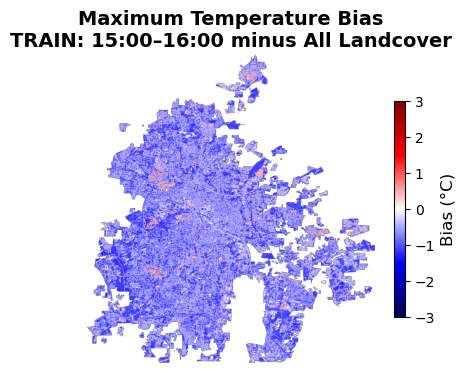

In [5]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

### Temporal bias examination 

base_dir = r"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\AT"

reference_set = 'All_LC'
comparison_set = 'Afternoon_trained'

tif_file = 'daily_mean_max.tif'


def read_raster(path):
    with rasterio.open(path) as src:
        return src.read(1)

# read in rasters 
reference_raster = read_raster(
    f"{base_dir}/{reference_set}/{tif_file}"
)

comparison_raster = read_raster(
    f"{base_dir}/{comparison_set}/{tif_file}"
)

# Calculate bias

bias = comparison_raster - reference_raster

print('Bias range:',
      np.nanmin(bias),
      np.nanmax(bias))


# Plot

fig, ax = plt.subplots(figsize=(5, 4))

im = ax.imshow(
    bias,
    cmap='seismic',
    vmin=-3,
    vmax=3
)

ax.axis('off')

ax.set_title(
    'Maximum Temperature Bias\nTRAIN: 15:00–16:00 minus All Landcover',
    fontsize=14,
    fontweight='bold'
)

# colorbar
cbar = plt.colorbar(
    im,
    ax=ax,
    shrink=0.7
)

cbar.set_label('Bias (°C)', fontsize=12)

plt.savefig(
    'AT_bias_map_single.png',
    dpi=600,
    bbox_inches='tight'
)

plt.show()

Bias range: -1.8084984 1.258398


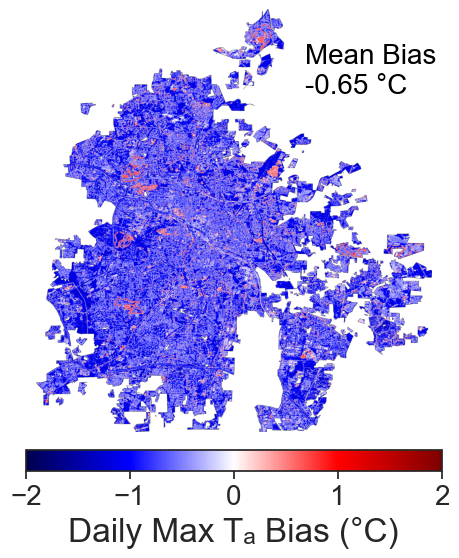

In [14]:
from matplotlib.ticker import MultipleLocator
# making more in line with other figs 

plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 25,
    'axes.labelsize': 25,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20
})


base_dir = r"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\AT"

reference_set = 'All_LC'
comparison_set = 'Afternoon_trained'

tif_file = 'daily_mean_max.tif'

subplot_labels = list(string.ascii_lowercase)

def read_raster(path):

    with rasterio.open(path) as src:

        arr = src.read(1)
        arr = np.where(arr == src.nodata, np.nan, arr)

    return arr

reference_raster = read_raster(
    f"{base_dir}/{reference_set}/{tif_file}"
)

comparison_raster = read_raster(
    f"{base_dir}/{comparison_set}/{tif_file}"
)


# Calculate bias

bias = comparison_raster - reference_raster

print(
    'Bias range:',
    np.nanmin(bias),
    np.nanmax(bias)
)

mean_bias = np.nanmean(bias)

#create plot 

fig, ax = plt.subplots(figsize=(6, 6))

im = ax.imshow(
    bias,
    cmap='seismic',
    vmin=-2,
    vmax=2
)

ax.axis('off')

# panel label
#ax.text(0.02, 1.05, f"({subplot_labels[0]})",transform=ax.transAxes,fontsize=25, fontweight="bold", va="top", ha="left")

# mean bias text
ax.text(
    0.68, 0.92,
    f"Mean Bias\n{mean_bias:.2f} °C",
    color="black",
    fontsize=20,
    ha='left',
    va='top',
    transform=ax.transAxes,
    bbox=dict(
        facecolor='white',
        alpha=0.6,
        edgecolor='none',
        boxstyle='round,pad=0.3'
    )
)


#ax.set_title('Daily Max Tₐ Bias\n15:00–16:00 Training',fontsize=28)

cbar = fig.colorbar(
    im,
    ax=ax,
    orientation="horizontal",
    fraction=0.045,
    pad=0.04
)

cbar.set_label('Daily Max Tₐ Bias (°C)', fontsize=24)

cbar.ax.xaxis.set_major_locator(
    MultipleLocator(1)
)

plt.savefig( r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\AT_bias_map_single.png',
                format='png',dpi=1200,bbox_inches='tight')

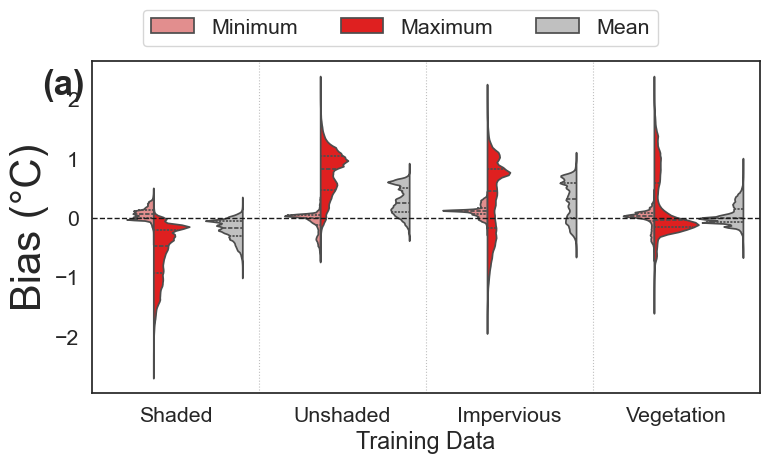

In [23]:
# violin plots 

base_dir = r"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\AT"
training_set_list = ['All_LC', 'Shaded_trained','Unshaded_trained','Impervious_trained', 'Vegetation_trained']
training_titles = ['All Landcover','Shaded','Unshaded','Impervious','Vegetation']
comparison_sets = training_set_list[1:]  # Compare against All_LC
tif_filename = ['daily_mean_min.tif','daily_mean_max.tif','hourly_mean.tif',]
metric_titles = ['Minimum','Maximum','Mean',]

color_palette = {
    "Minimum": "lightcoral", 
    "Maximum": "red", 
    "Mean": "silver"     
}


def read_raster(path):
    with rasterio.open(path) as src:
        return src.read(1)

bias_records = [] 

for i, tif_file in enumerate(tif_filename):
    all_lc_path = os.path.join(base_dir, "All_LC", tif_file)
    all_lc_data = read_raster(all_lc_path)
    
    for j, comp_set in enumerate(comparison_sets):
        comp_path = os.path.join(base_dir, comp_set, tif_file)
        comp_data = read_raster(comp_path)
        
        # Compute bias 
        bias = comp_data - all_lc_data 
        bias = bias[np.isfinite(bias)]
        
        # Store in tidy format for seaborn
        bias_records.extend([
            {"Metric": metric_titles[i], "Training": training_titles[j+1], "Bias (°C)": val}
            for val in bias
        ])

# Convert to DataFrame
bias_df = pd.DataFrame(bias_records)

#plot bias dataframe
sns.set_theme(style="white", font_scale=1.4)

plt.figure(figsize=(8,5))
sns.violinplot(
    data=bias_df,
    x="Training",
    y="Bias (°C)",
    hue="Metric",
    split=True,      # half-and-half per metric type
    inner="quartile", # show quartiles inside violin
    palette= color_palette
)

plt.axhline(0, color="k", linestyle="--", linewidth=1)
plt.ylabel("Bias (°C)", fontsize=30)
plt.xlabel("Training Data")
#plt.title("Distribution of Bias Relative to All_LC Model", fontsize=14, weight='bold')
plt.legend(loc='center left', bbox_to_anchor =(0.06,1.1), ncol = 3 )
plt.text( -0.8, plt.ylim()[1]*0.95,   "(a)",   fontsize=25, fontweight='bold', va='top')
#adding dotted line so its easier to tell the category 
ax = plt.gca()
for x in range(len(training_titles) - 1):  # one less than total
    ax.axvline(x + 0.5, color="gray", linestyle=":", linewidth=0.8, alpha=0.5)

plt.tight_layout()


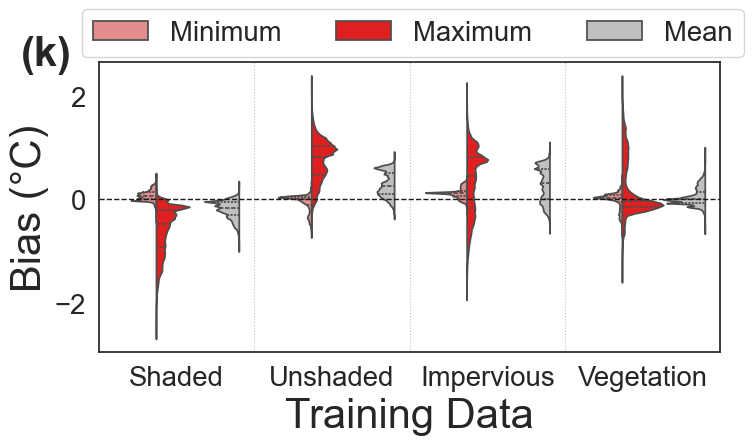

In [24]:
#plot bias dataframe
# Making text bigger etc. 
sns.set_theme(style="white", font_scale=1.8)

plt.figure(figsize=(8,5))
sns.violinplot(
    data=bias_df,
    x="Training",
    y="Bias (°C)",
    hue="Metric",
    split=True,      # half-and-half per metric type
    inner="quartile", # show quartiles inside violin
    palette= color_palette
)

plt.axhline(0, color="k", linestyle="--", linewidth=1)
plt.ylabel("Bias (°C)", fontsize=30)
plt.xlabel("Training Data", fontsize=30)
#plt.title("Distribution of Bias Relative to All_LC Model", fontsize=14, weight='bold')
plt.legend(loc='center left', bbox_to_anchor =(-0.05,1.1), ncol = 3 )
plt.text( -1, plt.ylim()[1]*1.2,   "(k)",   fontsize=30, fontweight='bold', va='top')
#adding dotted line so its easier to tell the category 
ax = plt.gca()
for x in range(len(training_titles) - 1):  # one less than total
    ax.axvline(x + 0.5, color="gray", linestyle=":", linewidth=0.8, alpha=0.5)

plt.tight_layout()

plt.savefig( r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\AT_training_bias_violin.png',
                format='png',dpi=1200,bbox_inches='tight')

In [25]:
import matplotlib.ticker as ticker

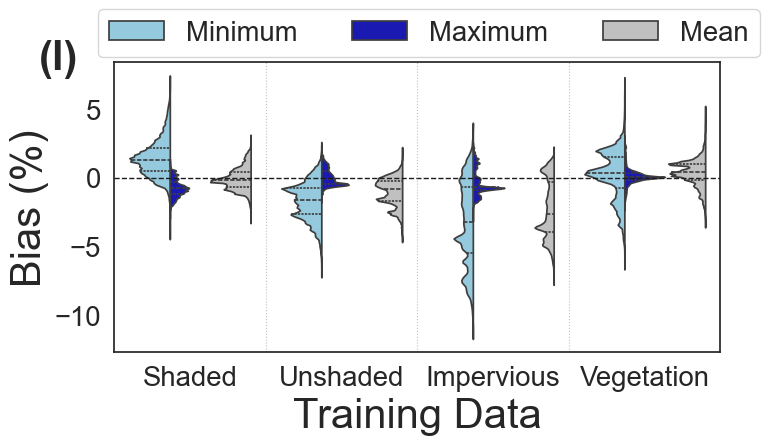

In [26]:
# violin plots 

base_dir = r"D:\DDL\Durham_ML\Absolute\Clipped\Summary_Rasters\RH"
training_set_list = ['All_LC', 'Shaded_trained','Unshaded_trained','Impervious_trained', 'Vegetation_trained']
training_titles = ['All Landcover','Shaded','Unshaded','Impervious','Vegetation']
comparison_sets = training_set_list[1:]  # Compare against All_LC
tif_filename = ['daily_mean_min.tif','daily_mean_max.tif','hourly_mean.tif',]
metric_titles = ['Minimum','Maximum','Mean',]

color_palette = {
    "Minimum": "skyblue", 
    "Maximum": "mediumblue", 
    "Mean": "silver"     
}


def read_raster(path):
    with rasterio.open(path) as src:
        return src.read(1)

bias_records = [] 

for i, tif_file in enumerate(tif_filename):
    all_lc_path = os.path.join(base_dir, "All_LC", tif_file)
    all_lc_data = read_raster(all_lc_path)
    
    for j, comp_set in enumerate(comparison_sets):
        comp_path = os.path.join(base_dir, comp_set, tif_file)
        comp_data = read_raster(comp_path)
        
        # Compute bias (ignore NaNs or nodata)
        bias = comp_data - all_lc_data
        bias = bias[np.isfinite(bias)]
        
        # Store in tidy format for seaborn
        bias_records.extend([
            {"Metric": metric_titles[i], "Training": training_titles[j+1], "Bias (%)": val}
            for val in bias
        ])

# Convert to DataFrame
bias_df = pd.DataFrame(bias_records)

#plot bias dataframe
sns.set_theme(style="white", font_scale=1.8)

plt.figure(figsize=(8,5))
sns.violinplot(
    data=bias_df,
    x="Training",
    y="Bias (%)",
    hue="Metric",
    split=True,      # half-and-half per metric type
    inner="quartile", # show quartiles inside violin
    palette= color_palette
)

plt.axhline(0, color="k", linestyle="--", linewidth=1)
plt.ylabel("Bias (%)", fontsize=30)
plt.xlabel("Training Data", fontsize=30)
#plt.title("Distribution of Bias Relative to All_LC Model", fontsize=14, weight='bold')
#plt.legend()
plt.legend(loc='center left', bbox_to_anchor =(-0.05,1.1), ncol = 3 )
plt.text( -1, plt.ylim()[1]*1.2,   "(l)",   fontsize=30, fontweight='bold', va='top')
#adding dotted line so its easier to tell the category 
ax = plt.gca()
for x in range(len(training_titles) - 1):  # one less than total
    ax.axvline(x + 0.5, color="gray", linestyle=":", linewidth=0.8, alpha=0.5)

plt.tight_layout()

plt.savefig( r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\RH_training_bias_violin.png',
                format='png',dpi=1200,bbox_inches='tight')